In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, ifft
from scipy.ndimage import center_of_mass, label
from skimage.measure import regionprops, find_contours
from skimage.morphology import convex_hull_image
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import warnings
import seaborn as sns
from ipywidgets import interact, IntSlider
import os


warnings.filterwarnings('ignore')


In [3]:

# ==========================================================
# CONSTANTS
# ==========================================================

px_to_um = 0.072
min_harmonics = 1
max_harmonics = 300

# ==========================================================
# POLAR EXTRACTION FROM CONTOUR (1° PER STEP)
# ==========================================================

def calculate_radii(region, center, num_angles=360):
    """
    Extrai r(θ) a partir do contorno real do grão,
    com amostragem angular fixa de 1°.
    """

    contours = find_contours(region.astype(float), 0.5)

    if len(contours) == 0:
        raise ValueError("Contorno não encontrado.")

    contour = max(contours, key=len)

    cy, cx = center

    y = contour[:, 0]
    x = contour[:, 1]

    x_rel = x - cx
    y_rel = y - cy

    angles = np.arctan2(y_rel, x_rel)
    angles = np.mod(angles, 2*np.pi)

    radii = np.sqrt(x_rel**2 + y_rel**2)

    order = np.argsort(angles)
    angles = angles[order]
    radii = radii[order]

    unique_angles, unique_indices = np.unique(angles, return_index=True)
    angles = unique_angles
    radii = radii[unique_indices]

    # Uniform angular grid (1 degree)
    theta_uniform = np.linspace(0, 2*np.pi, num_angles, endpoint=False)

    # Periodic resampling (without smoothing)
    radii_interp = np.interp(
        theta_uniform,
        angles,
        radii,
        period=2*np.pi
    )

    return theta_uniform, radii_interp * px_to_um


# ==========================================================
# FOURIER
# ==========================================================

def fourier_series(radii, num_harmonics):
    coeffs = fft(radii)
    coeffs[num_harmonics+1:-num_harmonics] = 0
    return np.real(ifft(coeffs))


def calculate_fourier_descriptors(radii, n_descriptors=64):
    fft_coeffs = fft(radii)
    D = np.abs(fft_coeffs) / len(fft_coeffs)
    return D[:n_descriptors]


def calculate_roughness_coefficients(coeffs, j, k):
    a_n = np.real(coeffs[j:k+1])
    b_n = np.imag(coeffs[j:k+1])
    return np.sqrt(0.5 * np.sum(a_n**2 + b_n**2))


# ==========================================================
# GEOMETRIC DESCRIPTORS
# ==========================================================

def calculate_geometric_descriptors(region):
    props = regionprops(region.astype(int))[0]

    area = props.area
    perimeter = props.perimeter

    CI = (4 * np.pi * area) / (perimeter ** 2) if perimeter > 0 else 0

    convex_hull = convex_hull_image(region)
    convex_props = regionprops(convex_hull.astype(int))[0]
    convex_perimeter = convex_props.perimeter

    if perimeter > convex_perimeter:
        RE = np.log(perimeter / (perimeter - convex_perimeter))
    else:
        RE = 0

    equivalent_radius = np.sqrt(area / np.pi)
    RO = equivalent_radius / (perimeter / (2 * np.pi)) if perimeter > 0 else 0

    return RO, CI, RE


# ==========================================================
# MAIN ANALYSIS
# ==========================================================

def analyze_grains(binary_mask):

    labels_array = label(binary_mask)[0]
    num_labels = np.max(labels_array)

    results = {
        'labels': [],
        'areas': [],
        'centers': [],
        'MAE': [],
        'MSE': [],
        'R2': [],
        'harmonics': [],
        'radii_real': [],
        'radii_fourier': [],
        'angles': [],
        'history': []   # <-- histórico de convergência por grão
    }

    for label_idx in range(1, num_labels + 1):

        region = (labels_array == label_idx)

        if np.sum(region) < 20:
            continue

        center = center_of_mass(region)
        area = np.sum(region) * (px_to_um ** 2)

        try:
            angles, radii = calculate_radii(region, center)
        except:
            continue

        target_r2 = 0.999
        epsilon = 1e-5

        best_harmonics = min_harmonics
        best_mse = float('inf')
        best_r2 = -np.inf
        best_radii_fourier = None
        previous_mse = None

        upper_limit = min(max_harmonics, len(radii)//2)

        # Grain evolution history
        grain_history = {
            "harmonics": [],
            "MSE": [],
            "R2": []
        }

        for num_harmonics in range(min_harmonics, upper_limit):

            radii_fourier_temp = fourier_series(radii, num_harmonics)

            mse = mean_squared_error(radii, radii_fourier_temp)
            r2 = r2_score(radii, radii_fourier_temp)

            # Store complete history
            grain_history["harmonics"].append(num_harmonics)
            grain_history["MSE"].append(mse)
            grain_history["R2"].append(r2)

            if r2 >= target_r2:
                best_harmonics = num_harmonics
                best_mse = mse
                best_r2 = r2
                best_radii_fourier = radii_fourier_temp
                break

            if previous_mse is not None:
                improvement = abs(previous_mse - mse) / previous_mse
                if improvement < epsilon:
                    break

            previous_mse = mse

            best_harmonics = num_harmonics
            best_mse = mse
            best_r2 = r2
            best_radii_fourier = radii_fourier_temp

        if best_radii_fourier is None:
            continue

        mae = mean_absolute_error(radii, best_radii_fourier)

        results['labels'].append(label_idx)
        results['areas'].append(area)
        results['centers'].append(center)
        results['MAE'].append(mae)
        results['MSE'].append(best_mse)
        results['R2'].append(best_r2)
        results['harmonics'].append(best_harmonics)
        results['radii_real'].append(radii)
        results['radii_fourier'].append(best_radii_fourier)
        results['angles'].append(angles)
        results['history'].append(grain_history)

        print(f"Grão {label_idx} | Harmônicos: {best_harmonics} | R²: {best_r2:.4f}")

    return results, labels_array


# ==========================================================
# DIRECT EXECUTION
# ==========================================================

if __name__ == "__main__":

    from PIL import Image

    #mask_path = "/home/victor/analise_sinais_2025/joelson/1GU2PA/projeto/lamina_artigo/faro_12_obj_2_5x.tif"
    mask_path = "/home/victor/analise_sinais_2025/joelson/2LFST1AM/saida_segmentacao_graos/08_graos_binaria_sem_borda_com_lacuna01.png"

    mask_img = Image.open(mask_path)
    mask_array = np.array(mask_img) > 0

    results = analyze_grains(mask_array)

    print("\nProcessamento finalizado.")

Grão 1 | Harmônicos: 35 | R²: 0.9990
Grão 2 | Harmônicos: 134 | R²: 0.9990
Grão 4 | Harmônicos: 153 | R²: 0.9990
Grão 5 | Harmônicos: 163 | R²: 0.9991
Grão 6 | Harmônicos: 169 | R²: 0.9990
Grão 7 | Harmônicos: 83 | R²: 0.9990
Grão 8 | Harmônicos: 74 | R²: 0.9990
Grão 9 | Harmônicos: 160 | R²: 0.9990
Grão 10 | Harmônicos: 173 | R²: 0.9993
Grão 11 | Harmônicos: 177 | R²: 0.9991
Grão 12 | Harmônicos: 70 | R²: 0.9991
Grão 13 | Harmônicos: 53 | R²: 0.9990
Grão 14 | Harmônicos: 64 | R²: 0.9950
Grão 15 | Harmônicos: 83 | R²: 0.9990
Grão 16 | Harmônicos: 162 | R²: 0.9990
Grão 17 | Harmônicos: 47 | R²: 0.9991
Grão 18 | Harmônicos: 179 | R²: 0.9997
Grão 19 | Harmônicos: 159 | R²: 0.9990
Grão 20 | Harmônicos: 91 | R²: 0.9990
Grão 21 | Harmônicos: 46 | R²: 0.9990
Grão 22 | Harmônicos: 38 | R²: 0.9991
Grão 23 | Harmônicos: 52 | R²: 0.9990
Grão 24 | Harmônicos: 84 | R²: 0.9990
Grão 25 | Harmônicos: 55 | R²: 0.9990
Grão 26 | Harmônicos: 46 | R²: 0.9990
Grão 27 | Harmônicos: 56 | R²: 0.9991
Grão 29 | 

In [4]:
results, labels_array = analyze_grains(mask_array)

print("\nProcessamento finalizado.")

Grão 1 | Harmônicos: 35 | R²: 0.9990
Grão 2 | Harmônicos: 134 | R²: 0.9990
Grão 4 | Harmônicos: 153 | R²: 0.9990
Grão 5 | Harmônicos: 163 | R²: 0.9991
Grão 6 | Harmônicos: 169 | R²: 0.9990
Grão 7 | Harmônicos: 83 | R²: 0.9990
Grão 8 | Harmônicos: 74 | R²: 0.9990
Grão 9 | Harmônicos: 160 | R²: 0.9990
Grão 10 | Harmônicos: 173 | R²: 0.9993
Grão 11 | Harmônicos: 177 | R²: 0.9991
Grão 12 | Harmônicos: 70 | R²: 0.9991
Grão 13 | Harmônicos: 53 | R²: 0.9990
Grão 14 | Harmônicos: 64 | R²: 0.9950
Grão 15 | Harmônicos: 83 | R²: 0.9990
Grão 16 | Harmônicos: 162 | R²: 0.9990
Grão 17 | Harmônicos: 47 | R²: 0.9991
Grão 18 | Harmônicos: 179 | R²: 0.9997
Grão 19 | Harmônicos: 159 | R²: 0.9990
Grão 20 | Harmônicos: 91 | R²: 0.9990
Grão 21 | Harmônicos: 46 | R²: 0.9990
Grão 22 | Harmônicos: 38 | R²: 0.9991
Grão 23 | Harmônicos: 52 | R²: 0.9990
Grão 24 | Harmônicos: 84 | R²: 0.9990
Grão 25 | Harmônicos: 55 | R²: 0.9990
Grão 26 | Harmônicos: 46 | R²: 0.9990
Grão 27 | Harmônicos: 56 | R²: 0.9991
Grão 29 | 

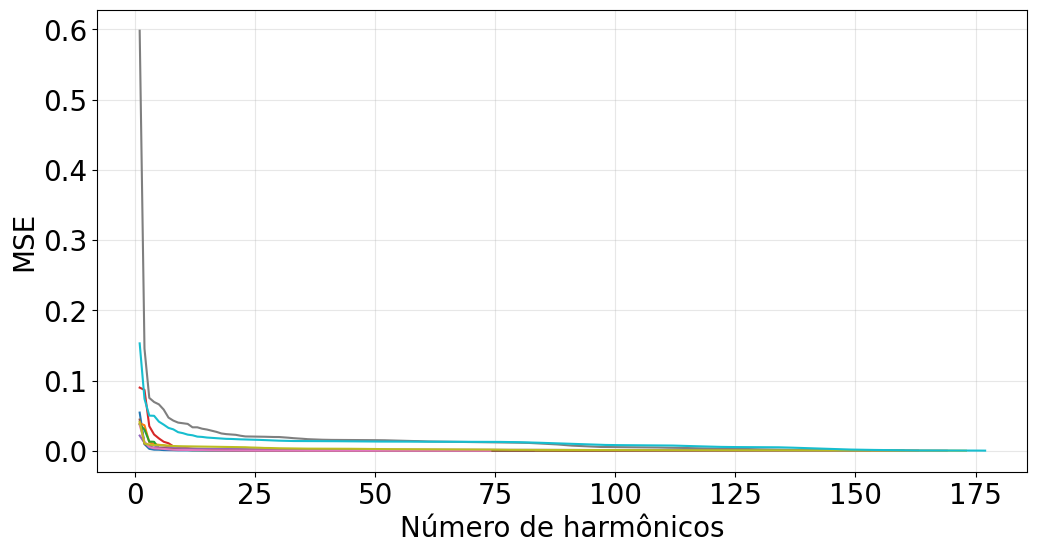

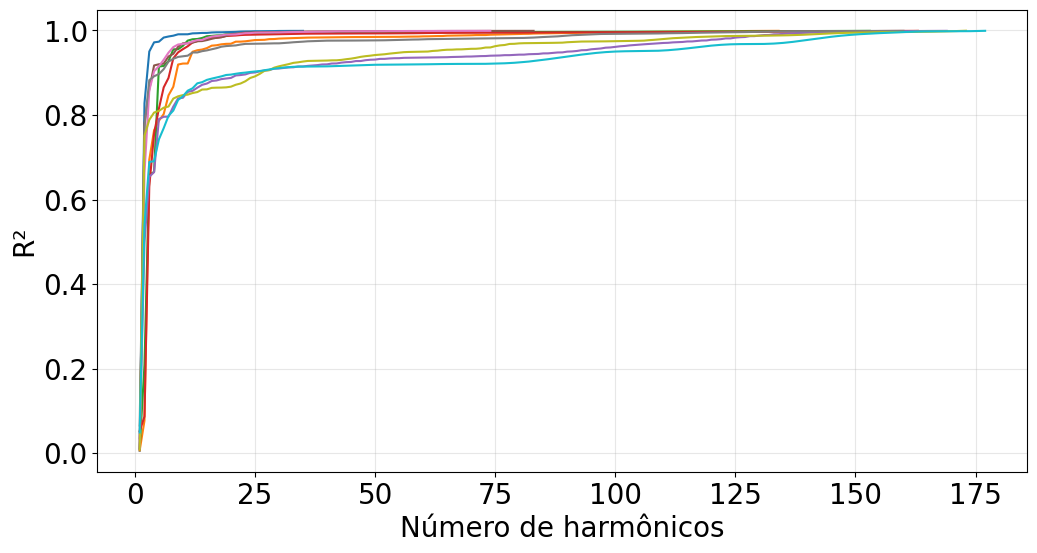

In [5]:
# ==========================================================
# EVOLUTION OF 10 GRAINS: MSE AND R² vs NUMBER OF HARMONICS
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np
import random

# ----------------------------------------------------------
# Selection of 10 grains
# ----------------------------------------------------------
n_grains_plot = 10

total_grains = len(results["labels"])
n_select = min(n_grains_plot, total_grains)

# Select the first 10 grains:
selected_indices = list(range(n_select))

# For random selection, use this line instead of the previous one:
# selected_indices = random.sample(range(total_grains), n_select)

# ----------------------------------------------------------
# PLOT 1 — MSE evolution
# ----------------------------------------------------------
plt.figure(figsize=(12, 6))

for idx in selected_indices:
    grain_label = results["labels"][idx]
    grain_history = results["history"][idx]

    plt.plot(
        grain_history["harmonics"],
        grain_history["MSE"],
        linewidth=1.5,
        label=f"Grão {grain_label}"
    )

plt.xlabel("Número de harmônicos", fontsize=20)
plt.ylabel("MSE", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.title("Evolução do MSE com o aumento do número de harmônicos")
plt.grid(True, alpha=0.3)
#plt.legend(ncol=2, fontsize=9)
#plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# PLOT 2 — R² evolution
# ----------------------------------------------------------
plt.figure(figsize=(12, 6))

for idx in selected_indices:
    grain_label = results["labels"][idx]
    grain_history = results["history"][idx]

    plt.plot(
        grain_history["harmonics"],
        grain_history["R2"],
        linewidth=1.5,
        label=f"Grão {grain_label}"
    )

plt.xlabel("Número de harmônicos", fontsize=20)
plt.ylabel("R²", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.title("Evolução do R² com o aumento do número de harmônicos")
plt.grid(True, alpha=0.3)
#plt.legend(ncol=2, fontsize=9)
#plt.tight_layout()
plt.show()

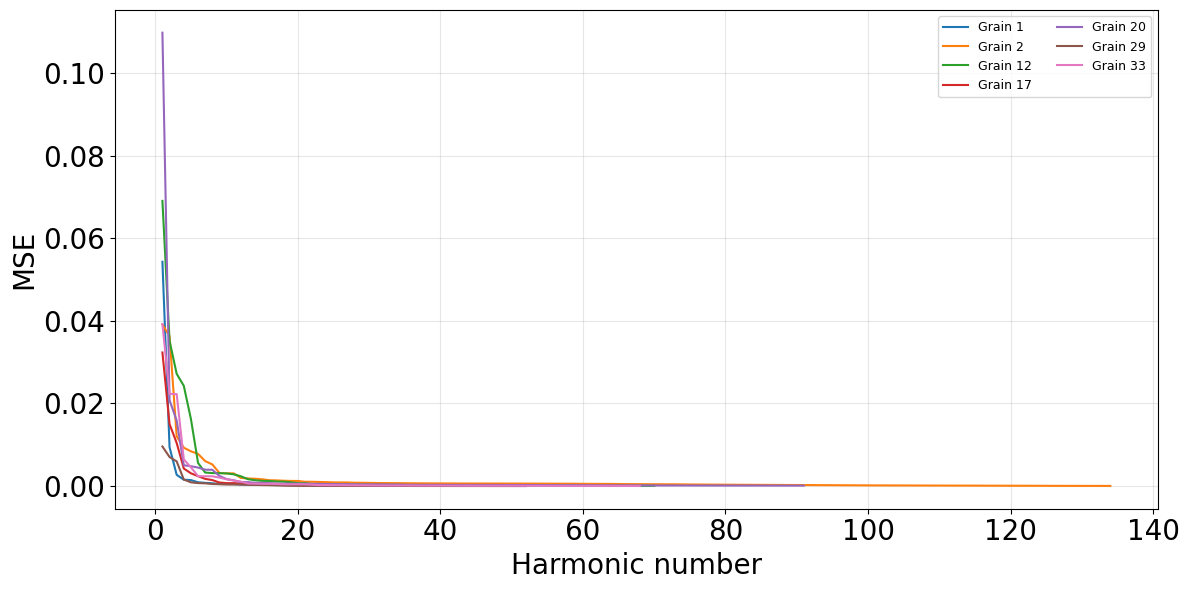

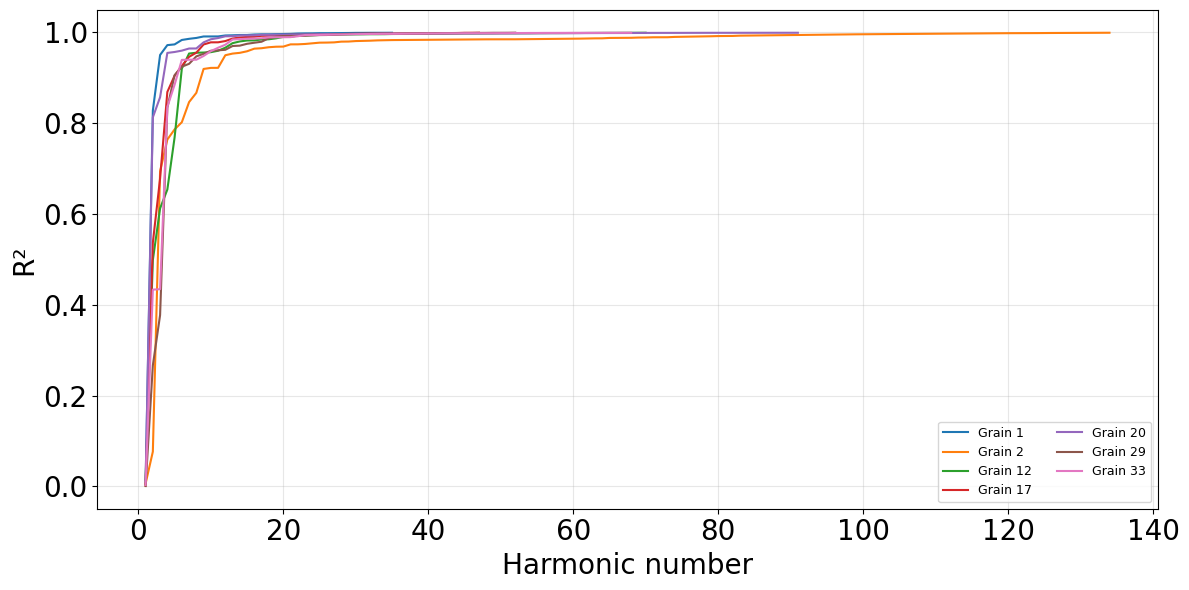

In [6]:
# Example: select 10 specific grains using their internal indices in results
selected_indices = [0, 1, 10, 15,18,26,30]

plt.figure(figsize=(12, 6))
for idx in selected_indices:
    grain_label = results["labels"][idx]
    grain_history = results["history"][idx]
    plt.plot(grain_history["harmonics"], grain_history["MSE"], linewidth=1.5, label=f"Grain {grain_label}")

plt.xlabel("Harmonic number", fontsize=20)
plt.ylabel("MSE", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.title("Evolução do MSE com o aumento do número de harmônicos")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
for idx in selected_indices:
    grain_label = results["labels"][idx]
    grain_history = results["history"][idx]
    plt.plot(grain_history["harmonics"], grain_history["R2"], linewidth=1.5, label=f"Grain {grain_label}")

plt.xlabel("Harmonic number", fontsize=20)
plt.ylabel("R²", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.title("Evolução do R² com o aumento do número de harmônicos")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

In [7]:
# ==========================================================
# VISUALIZATION: ACTUAL GRAIN vs EXTRACTED CONTOUR
# ==========================================================


def plot_real_vs_contour(results, labels_array, px_to_um):

    if len(results['labels']) == 0:
        print("Nenhum grão válido encontrado.")
        return

    def _plot(grain_index):

        idx = grain_index - 1
        label_id = results['labels'][idx]

        region = (labels_array == label_id)

        angles = results['angles'][idx]
        radii = results['radii_real'][idx]
        center = results['centers'][idx]
        cy, cx = center

        # Polar → Cartesian conversion (back to pixel coordinates)
        x_contour = cx + (radii / px_to_um) * np.cos(angles)
        y_contour = cy + (radii / px_to_um) * np.sin(angles)

        # ======================================================
        # PLOT
        # ======================================================

        fig, ax = plt.subplots(1, 2, figsize=(10, 5))
        sns.axes_style('darkgrid')

        # 1) Actual mask
        ax[0].imshow(region, cmap='gray')
        ax[0].set_title(f'Grão {grain_index} - Máscara Real')
        ax[0].axis('off')

        # 2) Reconstructed polar contour
        ax[1].imshow(region, cmap='gray')
        ax[1].plot(x_contour, y_contour, 'r-', linewidth=1)
        ax[1].set_title('Contorno Polar Reconstruído')
        ax[1].axis('off')

        plt.tight_layout()
        plt.show()

    interact(
        _plot,
        grain_index=IntSlider(
            min=1,
            max=len(results['labels']),
            step=1,
            value=1,
            description='Grão'
        )
    )
results, labels_array = analyze_grains(mask_array)
plot_real_vs_contour(results, labels_array, px_to_um)

Grão 1 | Harmônicos: 35 | R²: 0.9990
Grão 2 | Harmônicos: 134 | R²: 0.9990
Grão 4 | Harmônicos: 153 | R²: 0.9990
Grão 5 | Harmônicos: 163 | R²: 0.9991
Grão 6 | Harmônicos: 169 | R²: 0.9990
Grão 7 | Harmônicos: 83 | R²: 0.9990
Grão 8 | Harmônicos: 74 | R²: 0.9990
Grão 9 | Harmônicos: 160 | R²: 0.9990
Grão 10 | Harmônicos: 173 | R²: 0.9993
Grão 11 | Harmônicos: 177 | R²: 0.9991
Grão 12 | Harmônicos: 70 | R²: 0.9991
Grão 13 | Harmônicos: 53 | R²: 0.9990
Grão 14 | Harmônicos: 64 | R²: 0.9950
Grão 15 | Harmônicos: 83 | R²: 0.9990
Grão 16 | Harmônicos: 162 | R²: 0.9990
Grão 17 | Harmônicos: 47 | R²: 0.9991
Grão 18 | Harmônicos: 179 | R²: 0.9997
Grão 19 | Harmônicos: 159 | R²: 0.9990
Grão 20 | Harmônicos: 91 | R²: 0.9990
Grão 21 | Harmônicos: 46 | R²: 0.9990
Grão 22 | Harmônicos: 38 | R²: 0.9991
Grão 23 | Harmônicos: 52 | R²: 0.9990
Grão 24 | Harmônicos: 84 | R²: 0.9990
Grão 25 | Harmônicos: 55 | R²: 0.9990
Grão 26 | Harmônicos: 46 | R²: 0.9990
Grão 27 | Harmônicos: 56 | R²: 0.9991
Grão 29 | 

interactive(children=(IntSlider(value=1, description='Grão', max=762, min=1), Output()), _dom_classes=('widget…

In [8]:
# ==========================================================
# INTERACTIVE GRAIN VISUALIZATION (POLAR COMPARISON)
# WITH DARKGRID BACKGROUND
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, IntSlider
import numpy as np

sns.set_style('darkgrid')

def plot_grain_analysis(results):

    if len(results['labels']) == 0:
        print("Nenhum grão válido encontrado.")
        return

    def _plot(grain_index):

        idx = grain_index - 1
        
        angles = results['angles'][idx]
        radii_real = results['radii_real'][idx]
        radii_fourier = results['radii_fourier'][idx]
        harmonics = results['harmonics'][idx]

        # ======================================================
        # FIGURE 1 — ACTUAL CONTOUR
        # ======================================================
        fig1 = plt.figure(figsize=(6, 6))
        ax1 = fig1.add_subplot(111, projection='polar')
        ax1.plot(angles, radii_real, linewidth=2)
        #ax1.set_title(f'Grain {grain_index} — real outline\nHarmonics: {harmonics}')
        ax1.grid(True)

        # Manual adjustment for better contrast
        ax1.set_facecolor('#EAEAF2')

        plt.tight_layout()
        plt.show()

        # ======================================================
        # FIGURE 2 — FOURIER SERIES MODEL
        # ======================================================
        fig2 = plt.figure(figsize=(6, 6))
        ax2 = fig2.add_subplot(111, projection='polar')
        ax2.plot(angles, radii_fourier, linewidth=2, color='red')
        #ax2.set_title(f'Grain {grain_index} — Série de Fourier\nHarmônicos: {harmonics}')
        ax2.grid(True)

        ax2.set_facecolor('#EAEAF2')

        plt.tight_layout()
        plt.show()

    interact(
        _plot,
        grain_index=IntSlider(
            min=1,
            max=len(results['labels']),
            step=1,
            value=1,
            description='Grão'
        )
    )

plot_grain_analysis(results)

interactive(children=(IntSlider(value=1, description='Grão', max=762, min=1), Output()), _dom_classes=('widget…

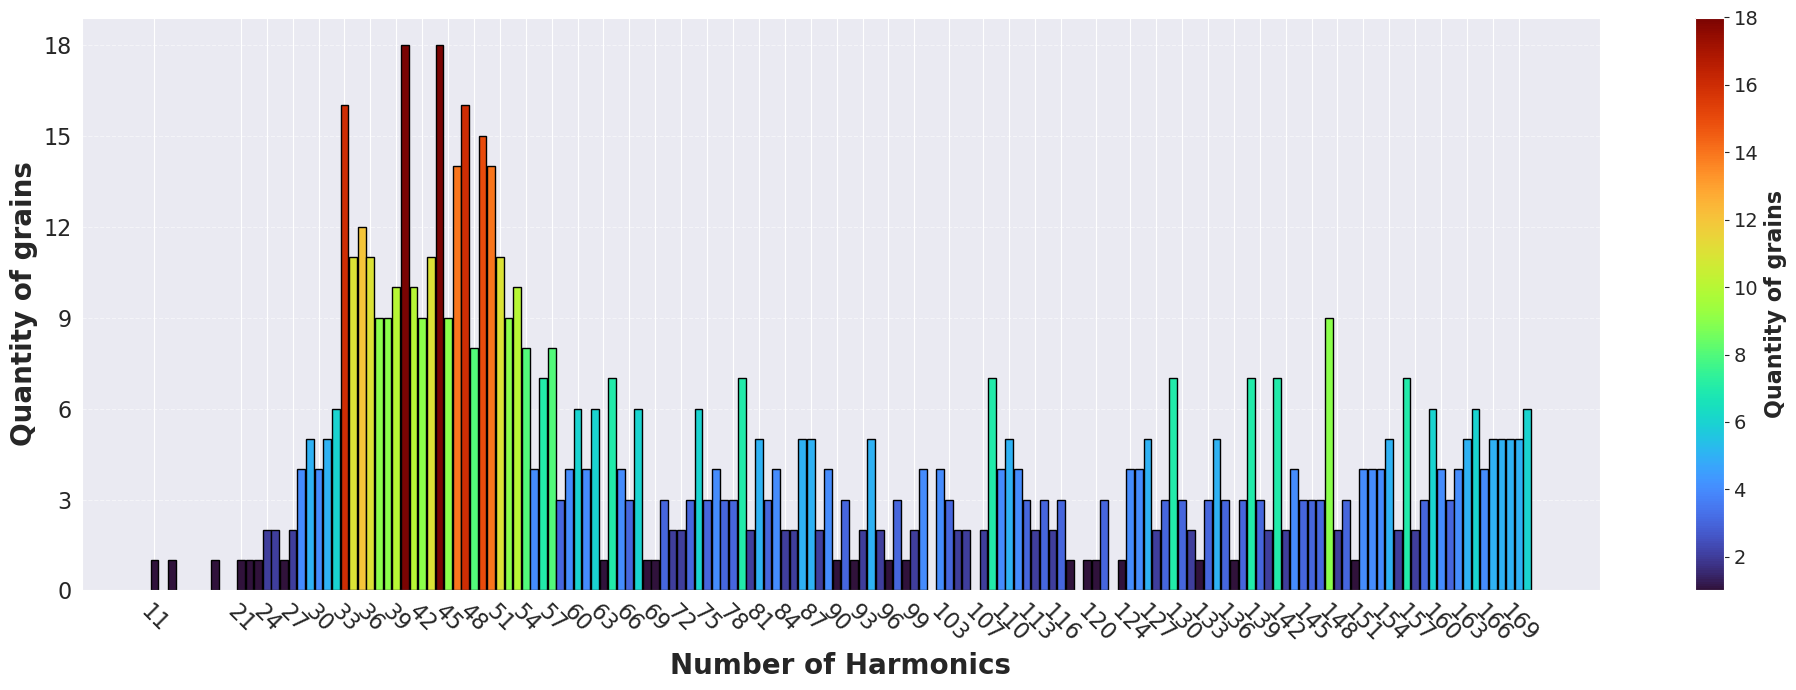

Resumo estatístico:
Média: 82.81
Mediana: 65.00
Desvio padrão: 45.63
Mínimo: 11
Máximo: 170


In [9]:
# ==========================================================
# HISTOGRAM GROUPED INTO INTERVALS WITH COLOR PALETTE
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

def plot_harmonics_histogram(results, max_harmonic=170, bin_width=1):
    harmonics = np.array(results['harmonics'])

    if len(harmonics) == 0:
        print("Nenhum grão válido foi processado.")
        return

    # -------------------------
    # Filtering
    # -------------------------
    filtered = harmonics[harmonics <= max_harmonic]

    if len(filtered) == 0:
        print("Nenhum grão dentro do limite especificado.")
        return

    # -------------------------
    # Count by integer harmonic value
    # -------------------------
    values, counts = np.unique(filtered, return_counts=True)

    # To group into bins wider than 1
    if bin_width > 1:
        bin_edges = np.arange(values.min(), values.max() + bin_width, bin_width)
        hist_counts, edges = np.histogram(filtered, bins=bin_edges)
        centers = (edges[:-1] + edges[1:]) / 2

        # Keep only bins actually used
        mask = hist_counts > 0
        x_vals = centers[mask]
        y_vals = hist_counts[mask]
        widths = np.diff(edges)[mask]
    else:
        x_vals = values
        y_vals = counts
        widths = np.full_like(x_vals, 0.9, dtype=float)

    # -------------------------
    # Map colors according to frequency
    # -------------------------
    norm = Normalize(vmin=np.min(y_vals), vmax=np.max(y_vals))
    cmap = cm.get_cmap("turbo")
    colors = cmap(norm(y_vals))

    # -------------------------
    # Plot
    # -------------------------
    plt.figure(figsize=(20, 7))
    bars = plt.bar(
        x_vals,
        y_vals,
        width=widths,
        color=colors,
        edgecolor="black",
        align="center"
    )

    plt.xlabel("Number of Harmonics", fontsize=20, fontweight="bold")
    plt.ylabel("Quantity of grains", fontsize=20, fontweight="bold")

    # -------------------------
    # X-axis: display only used values
    # -------------------------
    if len(x_vals) <= 40:
        plt.xticks(x_vals, rotation=-45, fontsize=16)
    else:
        step = max(1, len(x_vals) // 40)
        plt.xticks(x_vals[::step], rotation=-45, fontsize=16)

    # -------------------------
    # Y-axis
    # -------------------------
    y_max = np.max(y_vals)
    step_y = max(1, int(np.ceil(y_max / 8)))
    plt.yticks(np.arange(0, y_max + step_y, step_y), fontsize=16)

    # -------------------------
    # Colorbar
    # -------------------------
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm)
    cbar.set_label("Quantity of grains", fontsize=16, fontweight="bold")
    cbar.ax.tick_params(labelsize=14)

    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # -------------------------
    # Additional statistics
    # -------------------------
    print("Resumo estatístico:")
    print(f"Média: {np.mean(filtered):.2f}")
    print(f"Mediana: {np.median(filtered):.2f}")
    print(f"Desvio padrão: {np.std(filtered):.2f}")
    print(f"Mínimo: {np.min(filtered)}")
    print(f"Máximo: {np.max(filtered)}")


plot_harmonics_histogram(results, max_harmonic=170, bin_width=1)

In [10]:
# ==========================================================
# VISUALIZATION OF r(θ) IN CARTESIAN FORMAT (ANGLE × RADIUS)
# ==========================================================

def plot_radial_function(results):

    if len(results['labels']) == 0:
        print("Nenhum grão válido encontrado.")
        return

    def _plot(grain_index):

        idx = grain_index - 1

        angles = results['angles'][idx]
        radii_real = results['radii_real'][idx]
        radii_fourier = results['radii_fourier'][idx]
        harmonics = results['harmonics'][idx]
        r2 = results['R2'][idx]

        # Convert angle to degrees
        angles_deg = np.degrees(angles)

        # Ensure ascending order (numerical robustness)
        order = np.argsort(angles_deg)
        angles_deg = angles_deg[order]
        radii_real = radii_real[order]
        radii_fourier = radii_fourier[order]

        # ======================================================
        # PLOT
        # ======================================================

        fig, ax = plt.subplots(1, 2, figsize=(18, 4))
        sns.axes_style('darkgrid')

        # -----------------------------
        # 1) ACTUAL CONTOUR
        # -----------------------------
        ax[0].plot(angles_deg, radii_real, label= 'Real outline', color='blue')
        ax[0].set_title(f'Grain {grain_index} - Real grain', fontsize= 18)
        ax[0].set_xlabel("Angle (degrees)", fontsize= 18)
        ax[0].set_ylabel("Raio (µm)", fontsize= 18)
        ax[0].set_xlim(0, 360)
        ax[0].tick_params(axis='both', labelsize=18)
        ax[0].grid(True)

        # -----------------------------
        # 2) FOURIER SERIES
        # -----------------------------
        ax[1].plot(angles_deg, radii_fourier, label= 'Fourier series', color='red')
        ax[1].set_title(
            f'Reconstruction using Fourier series\nNumber of harmonics: {harmonics}', fontsize= 18
        )
        ax[1].set_xlabel("Angle (degrees)", fontsize= 18)
        ax[1].set_ylabel("Distance (µm)", fontsize= 18)
        ax[1].set_xlim(0, 360)
        ax[1].tick_params(axis='both', labelsize=18)
        ax[1].grid(True)

        plt.tight_layout()
        plt.legend()
        plt.show()

    interact(
        _plot,
        grain_index=IntSlider(
            min=1,
            max=len(results['labels']),
            step=1,
            value=1,
            description='Grão'
        )
    )

plot_radial_function(results)

interactive(children=(IntSlider(value=1, description='Grão', max=762, min=1), Output()), _dom_classes=('widget…

In [ ]:
from scipy.ndimage import label
from skimage.measure import regionprops
from skimage.morphology import convex_hull_image

def calculate_shape_descriptors(binary_mask, px_to_um=1.0):

    labels_array = label(binary_mask)[0]
    num_labels = np.max(labels_array)

    descriptors = {
        "Label": [],
        "Área (µm²)": [],
        "Perímetro (µm)": [],
        "Circularidade": [],
        "Arredondamento": [],
        "Regularidade": []
    }

    for label_idx in range(1, num_labels + 1):

        region = (labels_array == label_idx)

        if np.sum(region) < 20:
            continue

        props = regionprops(region.astype(int))[0]

        # ---------------------------------
        # Area and perimeter (converted)
        # ---------------------------------
        area = props.area * (px_to_um ** 2)
        perimeter = props.perimeter * px_to_um

        if perimeter == 0:
            continue

        # ---------------------------------
        # 1) Circularity
        # ---------------------------------
        circularity = (4 * np.pi * area) / (perimeter ** 2)

        # ---------------------------------
        # 2) Roundness
        # ---------------------------------
        r_eq = np.sqrt(area / np.pi)
        r_per = perimeter / (2 * np.pi)
        roundness = r_eq / r_per

        # ---------------------------------
        # 3) Regularity (Convexity)
        # ---------------------------------
        convex = convex_hull_image(region)
        convex_props = regionprops(convex.astype(int))[0]
        convex_perimeter = convex_props.perimeter * px_to_um

        regularity = convex_perimeter / perimeter

        # ---------------------------------
        # Storage
        # ---------------------------------
        descriptors["Label"].append(label_idx)
        descriptors["Área (µm²)"].append(area)
        descriptors["Perímetro (µm)"].append(perimeter)
        descriptors["Circularidade"].append(circularity)
        descriptors["Arredondamento"].append(roundness)
        descriptors["Regularidade"].append(regularity)

    df_descriptors = pd.DataFrame(descriptors)

    print("Cálculo finalizado.")
    print(f"Total de grãos analisados: {len(df_descriptors)}")

    return df_descriptors


# ==========================================================
# EXECUTION
# ==========================================================

df_shape = calculate_shape_descriptors(mask_array, px_to_um)
df_shape.head()

Cálculo finalizado.
Total de grãos analisados: 762


,Label,Área (µm²),Perímetro (µm),Circularidade,Arredondamento,Regularidade
0,1,4.665600,8.586348,0.795244,0.891765,0.988141
1,2,2.239488,7.598377,0.487435,0.698166,0.959856
2,4,2.752704,7.652906,0.590631,0.768526,0.930580
3,5,5.406912,11.054816,0.555976,0.745638,0.968552
4,6,0.772416,4.337909,0.515822,0.718208,1.010313


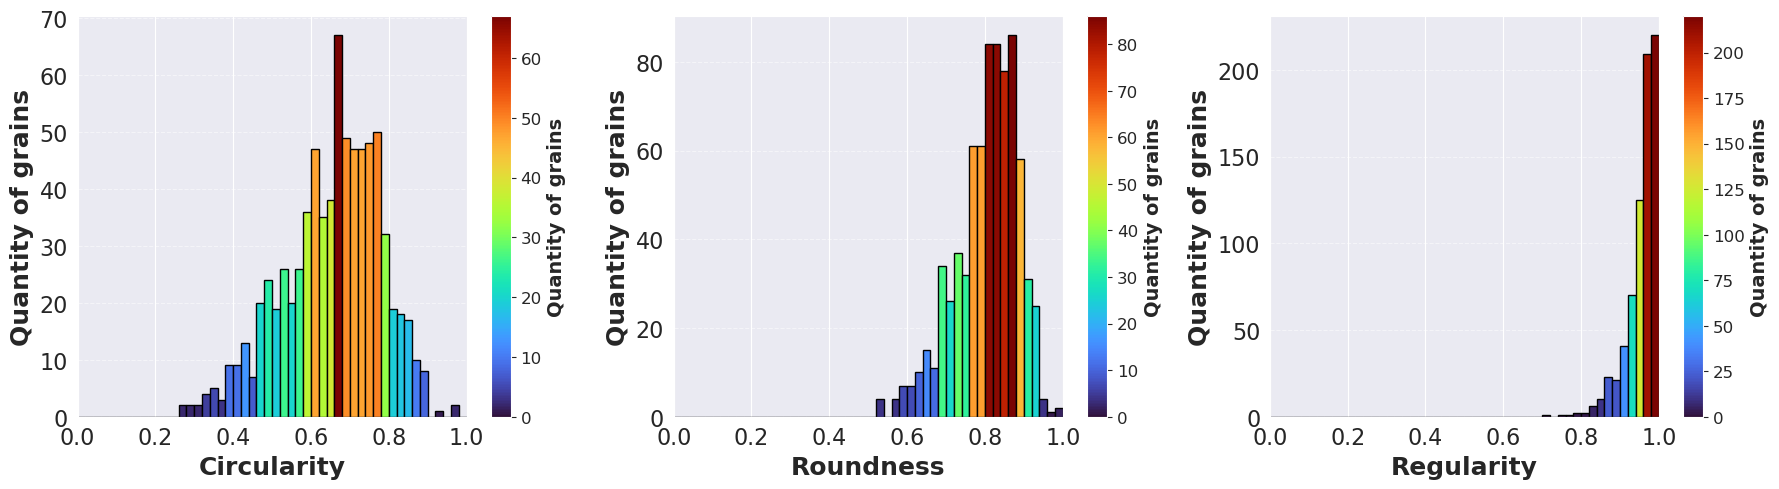


Resumo Estatístico:
       Circularidade  Arredondamento  Regularidade
count     762.000000      762.000000    762.000000
mean        0.653986        0.804686      0.958187
std         0.124876        0.080465      0.040917
min         0.272631        0.522140      0.708094
25%         0.579985        0.761568      0.943090
50%         0.668206        0.817439      0.967446
75%         0.746782        0.864165      0.984811
max         0.975670        0.987760      1.114615


In [12]:
# ==========================================================
# HISTOGRAMS WITH INTERPRETIVE AXIS AND COLOR VARIATION
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

def plot_shape_histograms_interpretative(df_shape, bins=25):

    if df_shape is None or len(df_shape) == 0:
        print("DataFrame vazio.")
        return

    descriptors = [
        ("Circularidade", "Circularity"),
        ("Arredondamento", "Roundness"),
        ("Regularidade", "Regularity")
    ]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (col, xlabel) in zip(axes, descriptors):

        data = df_shape[col].dropna().values

        # -------------------------
        # Manual histogram
        # -------------------------
        counts, edges = np.histogram(data, bins=bins, range=(0, 1))
        widths = np.diff(edges)
        centers = edges[:-1]

        # -------------------------
        # Map colors according to frequency
        # -------------------------
        norm = Normalize(vmin=np.min(counts), vmax=np.max(counts) if np.max(counts) > 0 else 1)
        cmap = cm.get_cmap("turbo")
        colors = cmap(norm(counts))

        # -------------------------
        # Plot bars
        # -------------------------
        ax.bar(
            centers,
            counts,
            width=widths,
            align="edge",
            color=colors,
            edgecolor="black"
        )

        ax.set_xlabel(xlabel, fontsize=18, fontweight="bold")
        ax.set_ylabel("Quantity of grains", fontsize=18, fontweight="bold")
        ax.set_xlim(0, 1)
        ax.tick_params(axis='both', labelsize=16)
        ax.grid(axis="y", linestyle="--", alpha=0.5)

        # -------------------------
        # Colorbar
        # -------------------------
        sm = cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax)
        cbar.set_label("Quantity of grains", fontsize=14, fontweight="bold")
        cbar.ax.tick_params(labelsize=12)

    plt.tight_layout()
    plt.show()

    print("\nResumo Estatístico:")
    print(df_shape[[d[0] for d in descriptors]].describe())


plot_shape_histograms_interpretative(df_shape, bins=50)

In [13]:
# ==========================================================
# DEFINITION OF THE FIXED POPULATION (H ≤ 170)
# ==========================================================

df_fourier = pd.DataFrame({
    "Label": results["labels"],
    "Harmônicos": results["harmonics"]
})

df_all = pd.merge(df_shape, df_fourier, on="Label", how="inner")

# 🔹 MAIN FILTER
df_base = df_all[df_all["Harmônicos"] <= 170].copy()

N = len(df_base)

print(f"Total de grãos considerados (H ≤ 170): {N}")


# ----------------------------------------------------------
# STANDARD FUNCTION (WITHOUT RECALCULATING N)
# ----------------------------------------------------------

def frequency_table_fixed(data, bins, labels):

    categories = pd.cut(
        data,
        bins=bins,
        labels=labels,
        include_lowest=True,
        right=True
    )

    freq_abs = categories.value_counts().sort_index()
    freq_rel = (freq_abs / N) * 100
    freq_acum = freq_rel.cumsum()

    table = pd.DataFrame({
        "Frequência Absoluta": freq_abs,
        "Frequência (%)": freq_rel.round(2),
        "Frequência Acumulada (%)": freq_acum.round(2)
    })

    return table


# ==========================================================
# 1️⃣ HARMONICS
# ==========================================================

bins_h = [0, 70, 100, 150, 170]
labels_h = ["0–70", "71–100", "101–150", "151–170"]

table_harmonics = frequency_table_fixed(
    df_base["Harmônicos"],
    bins_h,
    labels_h
)

print("\n========== HARMÔNICOS ==========\n")
display(table_harmonics)


# ==========================================================
# 2️⃣ CIRCULARITY
# ==========================================================

bins_ci = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
labels_ci = ["0.0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"]

table_circularity = frequency_table_fixed(
    df_base["Circularidade"],
    bins_ci,
    labels_ci
)

print("\n========== CIRCULARIDADE ==========\n")
display(table_circularity)


# ==========================================================
# 3️⃣ ROUNDNESS
# ==========================================================

bins_ro = [0.30, 0.50, 0.70, 0.85, 1.0]
labels_ro = ["0.30–0.50", "0.50–0.70", "0.70–0.85", "0.85–1.0"]

table_roundness = frequency_table_fixed(
    df_base["Arredondamento"],
    bins_ro,
    labels_ro
)

print("\n========== ARREDONDAMENTO ==========\n")
display(table_roundness)


# ==========================================================
# 4️⃣ REGULARITY
# ==========================================================

bins_re = [0.50, 0.70, 0.85, 0.95, 1.0]
labels_re = ["0.50–0.70", "0.70–0.85", "0.85–0.95", "0.95–1.0"]

table_regularity = frequency_table_fixed(
    df_base["Regularidade"],
    bins_re,
    labels_re
)

print("\n========== REGULARIDADE ==========\n")
display(table_regularity)

Total de grãos considerados (H ≤ 170): 692

========== HARMÔNICOS ==========



,Frequência Absoluta,Frequência (%),Frequência Acumulada (%)
0–70,363,52.46,52.46
71–100,92,13.29,65.75
101–150,148,21.39,87.14
151–170,89,12.86,100.00



========== CIRCULARIDADE ==========



,Frequência Absoluta,Frequência (%),Frequência Acumulada (%)
0.0–0.2,0,0.00,0.00
0.2–0.4,7,1.01,1.01
0.4–0.6,159,22.98,23.99
0.6–0.8,451,65.17,89.16
0.8–1.0,75,10.84,100.00



========== ARREDONDAMENTO ==========



,Frequência Absoluta,Frequência (%),Frequência Acumulada (%)
0.30–0.50,0,0.00,0.00
0.50–0.70,47,6.79,6.79
0.70–0.85,405,58.53,65.32
0.85–1.0,240,34.68,100.00



========== REGULARIDADE ==========



,Frequência Absoluta,Frequência (%),Frequência Acumulada (%)
0.50–0.70,0,0.00,0.00
0.70–0.85,3,0.43,0.43
0.85–0.95,160,23.12,23.55
0.95–1.0,501,72.40,95.95


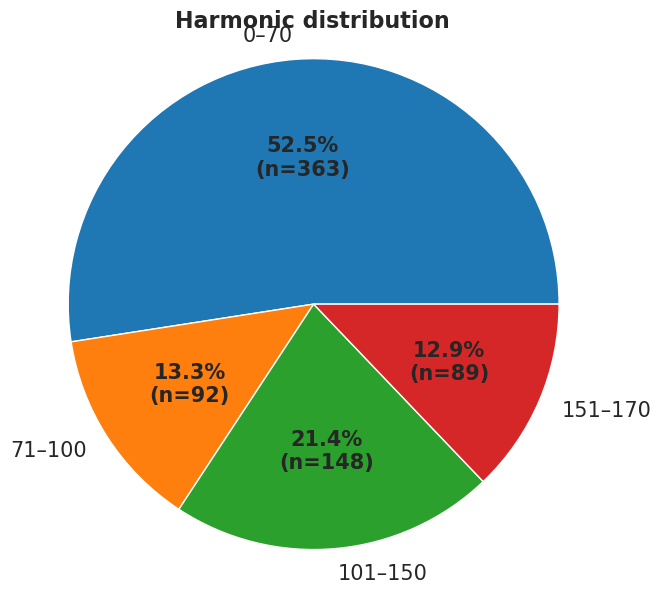

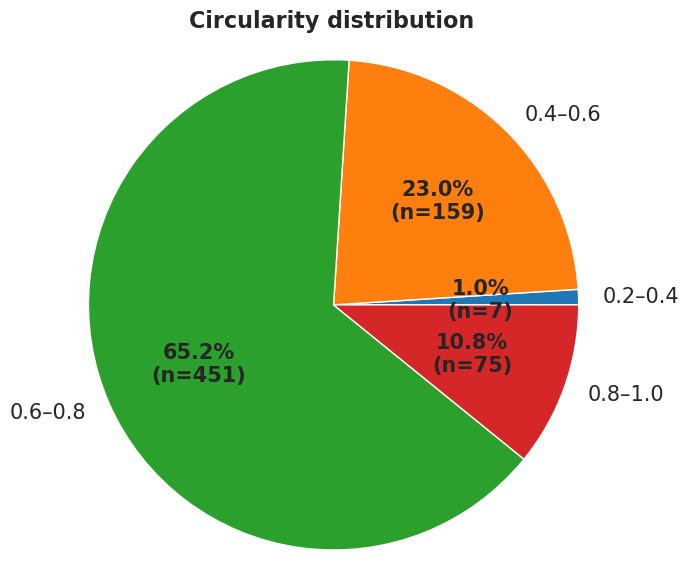

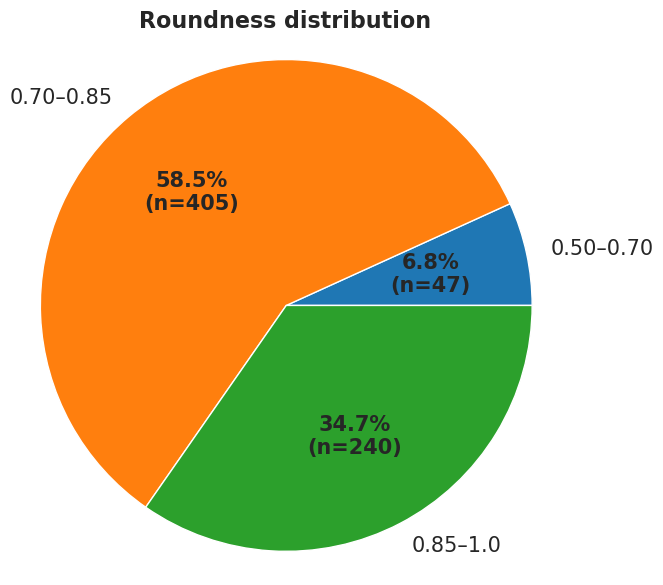

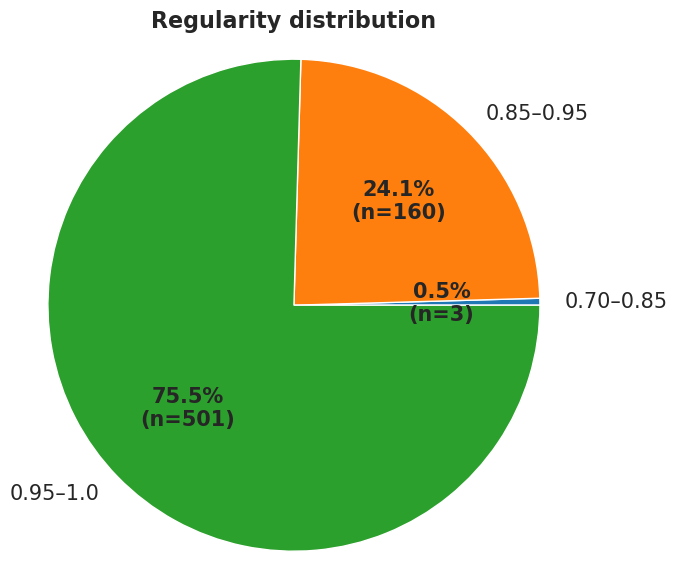

In [14]:
# ==========================================================
# FUNCTION TO DISPLAY % AND N
# ==========================================================
def autopct_with_counts(values):
    def inner(pct):
        total = sum(values)
        count = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n(n={count})"
    return inner


def pie_from_table_counts(table, title):
    freq_abs = table["Frequência Absoluta"]
    freq_abs = freq_abs[freq_abs > 0]

    plt.figure(figsize=(7, 7))
    wedges, texts, autotexts = plt.pie(
        freq_abs,
        labels=freq_abs.index,
        autopct=autopct_with_counts(freq_abs.values),
        startangle=0
    )

    # Class labels
    for text in texts:
        text.set_fontsize(15)
        

    # Percentages and counts
    for autotext in autotexts:
        autotext.set_fontsize(15)
        autotext.set_fontweight("bold")

    plt.title(title, fontsize=16, fontweight="bold")
    plt.axis("equal")
    plt.show()


pie_from_table_counts(table_harmonics, "Harmonic distribution")
pie_from_table_counts(table_circularity, "Circularity distribution")
pie_from_table_counts(table_roundness, "Roundness distribution")
pie_from_table_counts(table_regularity, "Regularity distribution")

Total de grãos avaliados: 692


,Label,Área (µm²),Perímetro (µm),Circularidade,Arredondamento,Regularidade,Harmônicos,Wadell,Powers,Folk
0,1,4.665600,8.586348,0.795244,0.891765,0.988141,35,Moderada,Rounded,Supermature
1,2,2.239488,7.598377,0.487435,0.698166,0.959856,134,Muito baixa,Rounded,Supermature
2,4,2.752704,7.652906,0.590631,0.768526,0.930580,153,Baixa,Rounded,Supermature
3,5,5.406912,11.054816,0.555976,0.745638,0.968552,163,Baixa,Rounded,Supermature
4,6,0.772416,4.337909,0.515822,0.718208,1.010313,169,Baixa,Rounded,Supermature



========== WADELL ==========



,Number of grains,Percentage (%),Frequência Acumulada (%)
Muito baixa,55,7.95,7.95
Baixa,339,48.99,56.94
Moderada,268,38.73,95.66
Alta,28,4.05,99.71
Muito alta,2,0.29,100.00



========== POWERS ==========



,Number of grains,Percentage (%),Frequência Acumulada (%)
Angular,0,0.0,0.0
Subangular,0,0.0,0.0
Subrounded,0,0.0,0.0
Rounded,692,100.0,100.0



========== FOLK ==========



,Number of grains,Percentage (%),Frequência Acumulada (%)
Immature,0,0.00,0.00
Submature,0,0.00,0.00
Mature,10,1.45,1.45
Supermature,682,98.55,100.00


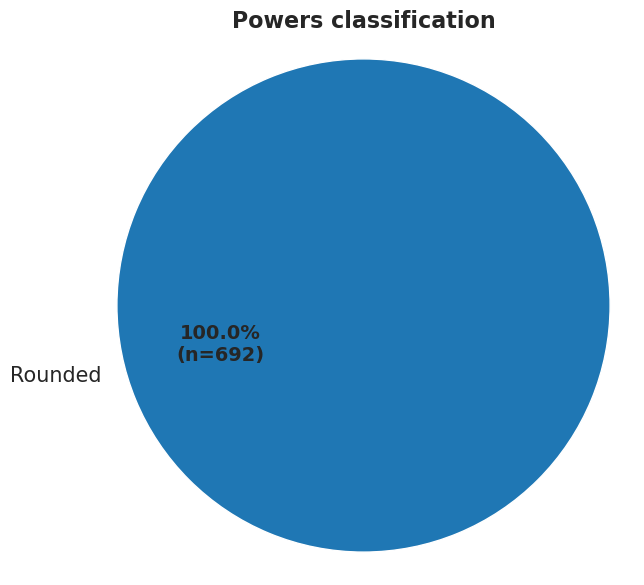

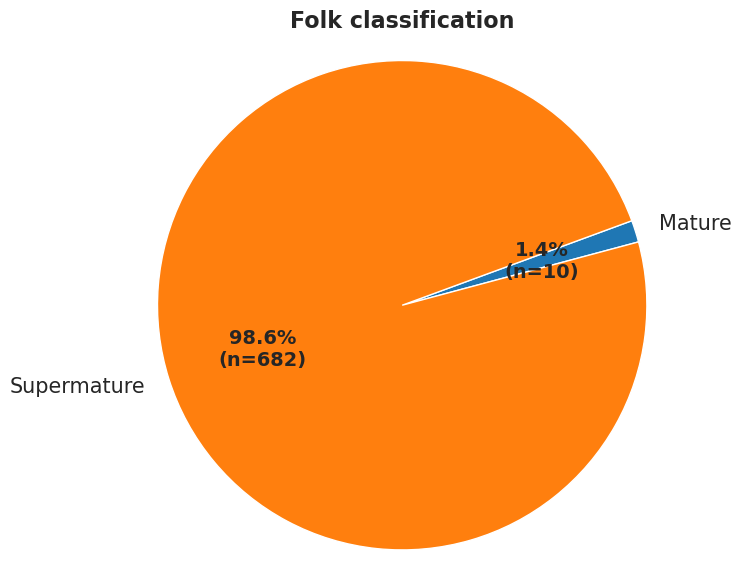

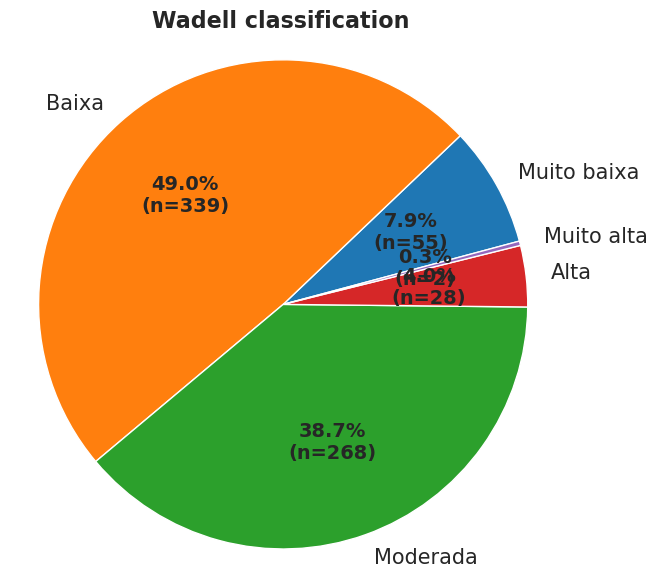

In [15]:
# ==========================================================
# WADELL, POWERS, AND FOLK METHODS
# INTEGRATED INTO THE OUTPUT ALREADY GENERATED IN THE NOTEBOOK
# Base: df_base
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1) CLASSIFICATION FUNCTIONS
# ----------------------------------------------------------

def classify_wadell(circularity):
    """
    Interpretação da esfericidade de Wadell
    a partir da circularidade calculada no código.
    """
    if circularity < 0.50:
        return "Muito baixa"
    elif circularity < 0.70:
        return "Baixa"
    elif circularity < 0.85:
        return "Moderada"
    elif circularity < 0.95:
        return "Alta"
    else:
        return "Muito alta"


def classify_powers(roundness):
    """
    Classificação de Powers com base no arredondamento.
    """
    if roundness < 0.15:
        return "Angular"
    elif roundness < 0.25:
        return "Subangular"
    elif roundness < 0.40:
        return "Subrounded"
    else:
        return "Rounded"


def classify_folk(roundness):
    """
    Classificação de Folk com base no arredondamento,
    interpretado como maturidade textural.
    """
    if roundness < 0.25:
        return "Immature"
    elif roundness < 0.45:
        return "Submature"
    elif roundness < 0.65:
        return "Mature"
    else:
        return "Supermature"


# ----------------------------------------------------------
# 2) CONSOLIDATED DATAFRAME
# ----------------------------------------------------------

df_models = df_base.copy()

df_models["Wadell"] = df_models["Circularidade"].apply(classify_wadell)
df_models["Powers"] = df_models["Arredondamento"].apply(classify_powers)
df_models["Folk"]   = df_models["Arredondamento"].apply(classify_folk)

print(f"Total de grãos avaliados: {len(df_models)}")
display(df_models.head())


# ----------------------------------------------------------
# 3) FUNCTION TO CREATE FREQUENCY TABLES
# ----------------------------------------------------------

def frequency_table_classes(series, ordered_classes):
    freq_abs = series.value_counts().reindex(ordered_classes, fill_value=0)
    freq_rel = (freq_abs / len(series)) * 100
    freq_acum = freq_rel.cumsum()

    table = pd.DataFrame({
        "Number of grains": freq_abs,
        "Percentage (%)": freq_rel.round(2),
        "Frequência Acumulada (%)": freq_acum.round(2)
    })
    return table


# ----------------------------------------------------------
# 4) TABLE - WADELL
# ----------------------------------------------------------

wadell_order = ["Muito baixa", "Baixa", "Moderada", "Alta", "Muito alta"]
table_wadell = frequency_table_classes(df_models["Wadell"], wadell_order)

print("\n========== WADELL ==========\n")
display(table_wadell)


# ----------------------------------------------------------
# 5) TABLE - POWERS
# ----------------------------------------------------------

powers_order = ["Angular", "Subangular", "Subrounded", "Rounded"]
table_powers = frequency_table_classes(df_models["Powers"], powers_order)

print("\n========== POWERS ==========\n")
display(table_powers)


# ----------------------------------------------------------
# 6) TABLE - FOLK
# ----------------------------------------------------------

folk_order = ["Immature", "Submature", "Mature", "Supermature"]
table_folk = frequency_table_classes(df_models["Folk"], folk_order)

print("\n========== FOLK ==========\n")
display(table_folk)


# ----------------------------------------------------------
# 7) FUNCTION TO PLOT PIE CHARTS
# ----------------------------------------------------------

def autopct_with_counts(values):
    def inner(pct):
        total = sum(values)
        count = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n(n={count})"
    return inner


def pie_from_class_table(table, title):
    freq_abs = table["Number of grains"]
    freq_abs = freq_abs[freq_abs > 0]

    plt.figure(figsize=(7, 7))
    wedges, texts, autotexts = plt.pie(
        freq_abs,
        labels=freq_abs.index,
        autopct=autopct_with_counts(freq_abs.values),
        startangle=15
    )

    for text in texts:
        text.set_fontsize(15)

    for autotext in autotexts:
        autotext.set_fontsize(14)
        autotext.set_fontweight("bold")

    plt.title(title, fontsize=16, fontweight="bold")
    plt.axis("equal")
    plt.show()


# ----------------------------------------------------------
# 8) PIE CHARTS
# ----------------------------------------------------------

pie_from_class_table(table_powers, "Powers classification")
pie_from_class_table(table_folk, "Folk classification")
pie_from_class_table(table_wadell, "Wadell classification")

In [16]:
# ==========================================================
# 9) FUNCTION TO SAVE RESULTS TO AN EXCEL SPREADSHEET
# Descriptors + Wadell, Powers, and Folk classifications
# ==========================================================

from openpyxl import Workbook

def salvar_resultados_descritores_modelos(
    df_models,
    table_wadell,
    table_powers,
    table_folk,
    output_path="resultados_descritores_modelos.xlsx"
):
    """
    Salva em uma planilha Excel:
    - dados individuais dos grãos com descritores e classificações
    - tabela de frequência Wadell
    - tabela de frequência Powers
    - tabela de frequência Folk
    """

    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        df_models.to_excel(
            writer,
            sheet_name="Graos_descritores_modelos",
            index=False
        )

        table_wadell.to_excel(
            writer,
            sheet_name="Tabela_Wadell"
        )

        table_powers.to_excel(
            writer,
            sheet_name="Tabela_Powers"
        )

        table_folk.to_excel(
            writer,
            sheet_name="Tabela_Folk"
        )

    print(f"Planilha salva com sucesso em: {output_path}")


# ==========================================================
# SAVE RESULTS
# ==========================================================

salvar_resultados_descritores_modelos(
    df_models=df_models,
    table_wadell=table_wadell,
    table_powers=table_powers,
    table_folk=table_folk,
    output_path="/home/victor/analise_sinais_2025/joelson/2LFST1AM/projeto/resultados_descritores_modelos_lamina_21_1gu1pa.xlsx"
)

Planilha salva com sucesso em: /home/victor/analise_sinais_2025/joelson/2LFST1AM/projeto/resultados_descritores_modelos_lamina_21_1gu1pa.xlsx


In [17]:
# ==========================================================
# OVERALL COMPARISON TABLE
# Fourier + geometric descriptors + Wadell + Powers + Folk
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# 1) HELPER FUNCTION FOR FREQUENCY TABLES
# ----------------------------------------------------------

def build_frequency_table_from_bins(series, bins, labels, method_name):
    """
    Cria tabela de frequência para variáveis contínuas
    como harmônicos e descritores geométricos.
    """
    classes = pd.cut(series, bins=bins, labels=labels, include_lowest=True, right=True)
    freq_abs = classes.value_counts().reindex(labels, fill_value=0)
    freq_rel = (freq_abs / len(series)) * 100
    freq_acum = freq_rel.cumsum()

    table = pd.DataFrame({
        "Método": method_name,
        "Classe / Intervalo": freq_abs.index,
        "Frequência Absoluta": freq_abs.values,
        "Percentage (%)": freq_rel.round(2).values,
        "Frequência Acumulada (%)": freq_acum.round(2).values
    })
    return table


# ----------------------------------------------------------
# 2) TABLES FOR THE METHODS
# ADJUST THE INTERVALS IF YOU WANT TO PRESERVE EXACTLY
# THE SAME FORMAT AS THE TABLES IN THE ARTICLE
# ----------------------------------------------------------

# Harmonics
harmonics_bins = [0, 70, 100, 150, 170, np.inf]
harmonics_labels = ["0–70", "71–100", "101–150", "151–170", ">170"]

table_harmonics = build_frequency_table_from_bins(
    df_base["Harmônicos"],
    bins=harmonics_bins,
    labels=harmonics_labels,
    method_name="Número de harmônicos"
)

# Circularity
circ_bins = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
circ_labels = ["0.0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"]

table_circularity = build_frequency_table_from_bins(
    df_base["Circularidade"],
    bins=circ_bins,
    labels=circ_labels,
    method_name="Circularidade"
)

# Roundness
round_bins = [0.30, 0.50, 0.70, 0.85, 1.00]
round_labels = ["0.30–0.50", "0.50–0.70", "0.70–0.85", "0.85–1.00"]

table_roundness = build_frequency_table_from_bins(
    df_base["Arredondamento"],
    bins=round_bins,
    labels=round_labels,
    method_name="Arredondamento"
)

# Regularity
reg_bins = [0.0, 0.25, 0.50, 0.75, 1.00]
reg_labels = ["0.00–0.25", "0.25–0.50", "0.50–0.75", "0.75–1.00"]

table_regularity = build_frequency_table_from_bins(
    df_base["Regularidade"],
    bins=reg_bins,
    labels=reg_labels,
    method_name="Regularidade"
)


# ----------------------------------------------------------
# 3) CONVERT CLASSICAL MODEL TABLES
# TO THE SAME FORMAT
# ----------------------------------------------------------

def convert_classification_table(table, method_name):
    """
    Converte table_wadell, table_powers e table_folk
    para o mesmo formato da tabela comparativa geral.
    """
    out = table.reset_index().rename(columns={"index": "Classe / Intervalo"}).copy()
    out.insert(0, "Método", method_name)
    return out[[
        "Método",
        "Classe / Intervalo",
        "Number of grains",
        "Percentage (%)",
        "Frequência Acumulada (%)"
    ]]

table_wadell_fmt = convert_classification_table(table_wadell, "Wadell")
table_powers_fmt = convert_classification_table(table_powers, "Powers")
table_folk_fmt   = convert_classification_table(table_folk, "Folk")


# ----------------------------------------------------------
# 4) MERGE ALL TABLES
# ----------------------------------------------------------

table_comparativa_geral = pd.concat([
    table_harmonics,
    table_circularity,
    table_roundness,
    table_regularity,
    table_wadell_fmt,
    table_powers_fmt,
    table_folk_fmt
], ignore_index=True)

display(table_comparativa_geral)


# ----------------------------------------------------------
# 5) OPTIONAL: SAVE CSV
# ----------------------------------------------------------

table_comparativa_geral.to_csv("/home/victor/analise_sinais_2025/joelson/2LFST1AM/projeto/tabela_comparativa_metodos.csv", index=False)
print("Tabela salva como: tabela_comparativa_metodos.csv")

,Método,Classe / Intervalo,Frequência Absoluta,Percentage (%),Frequência Acumulada (%),Number of grains
0,Número de harmônicos,0–70,363.0,52.46,52.46,NaN
1,Número de harmônicos,71–100,92.0,13.29,65.75,NaN
2,Número de harmônicos,101–150,148.0,21.39,87.14,NaN
3,Número de harmônicos,151–170,89.0,12.86,100.00,NaN
4,Número de harmônicos,>170,0.0,0.00,100.00,NaN
5,Circularidade,0.0–0.2,0.0,0.00,0.00,NaN
6,Circularidade,0.2–0.4,7.0,1.01,1.01,NaN
7,Circularidade,0.4–0.6,159.0,22.98,23.99,NaN
8,Circularidade,0.6–0.8,451.0,65.17,89.16,NaN
9,Circularidade,0.8–1.0,75.0,10.84,100.00,NaN


Tabela salva como: tabela_comparativa_metodos.csv


In [18]:
# ==========================================================
# TWO SEPARATE TABLES
# Table 1 = descriptors
# Table 2 = classical models
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# HELPER FUNCTION
# ----------------------------------------------------------

def build_frequency_table_from_bins(series, bins, labels, method_name):
    classes = pd.cut(series, bins=bins, labels=labels, include_lowest=True, right=True)
    freq_abs = classes.value_counts().reindex(labels, fill_value=0)
    freq_rel = (freq_abs / len(series)) * 100
    freq_acum = freq_rel.cumsum()

    table = pd.DataFrame({
        "Método": method_name,
        "Classe / Intervalo": freq_abs.index,
        "Number of grains": freq_abs.values,
        "Percentage (%)": freq_rel.round(2).values,
        "Frequência Acumulada (%)": freq_acum.round(2).values
    })
    return table


# ==========================================================
# TABLE 1 — DESCRIPTORS
# ==========================================================

# Adjust the intervals to match those already in use
harmonics_bins = [0, 70, 100, 150, 170, np.inf]
harmonics_labels = ["0–70", "71–100", "101–150", "151–170", ">170"]

circ_bins = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
circ_labels = ["0.0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"]

round_bins = [0.30, 0.50, 0.70, 0.85, 1.00]
round_labels = ["0.30–0.50", "0.50–0.70", "0.70–0.85", "0.85–1.00"]

reg_bins = [0.0, 0.25, 0.50, 0.75, 1.00]
reg_labels = ["0.00–0.25", "0.25–0.50", "0.50–0.75", "0.75–1.00"]

table_harmonics = build_frequency_table_from_bins(
    df_base["Harmônicos"], harmonics_bins, harmonics_labels, "Número de harmônicos"
)

table_circularity = build_frequency_table_from_bins(
    df_base["Circularidade"], circ_bins, circ_labels, "Circularidade"
)

table_roundness = build_frequency_table_from_bins(
    df_base["Arredondamento"], round_bins, round_labels, "Arredondamento"
)

table_regularity = build_frequency_table_from_bins(
    df_base["Regularidade"], reg_bins, reg_labels, "Regularidade"
)

tabela_1_descritores = pd.concat([
    table_harmonics,
    table_circularity,
    table_roundness,
    table_regularity
], ignore_index=True)

print("========== TABELA 1 — DESCRITORES ==========")
display(tabela_1_descritores)


# ==========================================================
# TABLE 2 — CLASSICAL MODELS
# ==========================================================

def summary_dominant_class(table, method_name, interpretation_dict=None):
    temp = table.reset_index().rename(columns={"index": "Classe"})
    row = temp.loc[temp["Number of grains"].idxmax()]

    interpretation = ""
    if interpretation_dict is not None:
        interpretation = interpretation_dict.get(row["Classe"], "")

    return pd.DataFrame([{
        "Método": method_name,
        "Classe dominante": row["Classe"],
        "Number of grains": int(row["Number of grains"]),
        "Percentage (%)": round(float(row["Percentage (%)"]), 2),
        "Interpretação": interpretation
    }])


wadell_interp = {
    "Muito baixa": "Grãos muito pouco esféricos",
    "Baixa": "Grãos pouco esféricos e alongados",
    "Moderada": "Forma intermediária",
    "Alta": "Grãos relativamente equilibrados",
    "Muito alta": "Grãos quase esféricos"
}

powers_interp = {
    "Angular": "Transporte muito curto",
    "Subangular": "Baixa abrasão",
    "Subrounded": "Abrasão moderada",
    "Rounded": "Abrasão intensa e transporte prolongado"
}

folk_interp = {
    "Immature": "Sedimentos pouco retrabalhados",
    "Submature": "Maturidade intermediária",
    "Mature": "Sedimentos bem retrabalhados",
    "Supermature": "Sedimentos altamente maduros e retrabalhados"
}

tabela_2_modelos = pd.concat([
    summary_dominant_class(table_wadell, "Wadell", wadell_interp),
    summary_dominant_class(table_powers, "Powers", powers_interp),
    summary_dominant_class(table_folk, "Folk", folk_interp)
], ignore_index=True)

print("========== TABELA 2 — MODELOS CLÁSSICOS ==========")
display(tabela_2_modelos)

========== TABELA 1 — DESCRITORES ==========


,Método,Classe / Intervalo,Number of grains,Percentage (%),Frequência Acumulada (%)
0,Número de harmônicos,0–70,363,52.46,52.46
1,Número de harmônicos,71–100,92,13.29,65.75
2,Número de harmônicos,101–150,148,21.39,87.14
3,Número de harmônicos,151–170,89,12.86,100.00
4,Número de harmônicos,>170,0,0.00,100.00
5,Circularidade,0.0–0.2,0,0.00,0.00
6,Circularidade,0.2–0.4,7,1.01,1.01
7,Circularidade,0.4–0.6,159,22.98,23.99
8,Circularidade,0.6–0.8,451,65.17,89.16
9,Circularidade,0.8–1.0,75,10.84,100.00


========== TABELA 2 — MODELOS CLÁSSICOS ==========


,Método,Classe dominante,Number of grains,Percentage (%),Interpretação
0,Wadell,Baixa,339,48.99,Grãos pouco esféricos e alongados
1,Powers,Rounded,692,100.00,Abrasão intensa e transporte prolongado
2,Folk,Supermature,682,98.55,Sedimentos altamente maduros e retrabalhados


In [21]:
# ================================================================
# 3 × 3 SECTOR ANALYSIS — FOURIER MODEL
# Based directly on fourier_modelo_final / Código colado.py
#
# Grid:
#
# NORTH
#
#        NW |  N  | NE
#       ----+-----+----
#         W |  C  |  E
#       ----+-----+----
#        SW |  S  | SE
#
# The spatial division covers THE ENTIRE MASK EXTENT.
# Descriptors are retrieved directly from `results`.
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle


# ================================================================
# 1. CHECK FOURIER MODEL VARIABLES
# ================================================================

print("=" * 80)
print("ANÁLISE SETORIAL — MODELO FOURIER")
print("=" * 80)

variaveis_necessarias = [
    "results",
    "mask_array"
]

for variavel in variaveis_necessarias:

    if variavel not in globals():

        raise NameError(
            f"\nA variável '{variavel}' não está disponível.\n"
            f"Execute primeiro a célula principal do modelo Fourier."
        )


# ================================================================
# 2. CHECK RESULT STRUCTURE
# ================================================================

chaves_necessarias = [
    "labels",
    "centers",
    "areas",
    "MAE",
    "MSE",
    "R2",
    "harmonics",
    "roughness_coeffs",
    "geometric_descriptors"
]

for chave in chaves_necessarias:

    if chave not in results:

        raise KeyError(
            f"O dicionário results não possui a chave '{chave}'."
        )


# ================================================================
# 3. ENSURE THE MASK IS 2D
# ================================================================

mask_setorial = np.asarray(mask_array)

if mask_setorial.ndim > 2:

    # If an extra channel exists
    if mask_setorial.shape[-1] in [3, 4]:

        mask_setorial = np.any(
            mask_setorial[..., :3] > 0,
            axis=-1
        )

    else:

        raise ValueError(
            f"A máscara possui dimensão inesperada: "
            f"{mask_setorial.shape}"
        )

else:

    mask_setorial = mask_setorial > 0


# ================================================================
# 4. ACTUAL THIN-SECTION / MASK DIMENSIONS
# ================================================================

altura, largura = mask_setorial.shape

print("\nDimensões utilizadas para a divisão setorial:")
print(f"  Altura  : {altura} pixels")
print(f"  Largura : {largura} pixels")


# ================================================================
# 5. 3 × 3 GRID BOUNDARIES
#
# IMPORTANT:
# We do not use centroid min/max values.
#
# The grid covers the entire image/mask extent.
# ================================================================

x0 = 0
x1 = largura / 3
x2 = 2 * largura / 3
x3 = largura

y0 = 0
y1 = altura / 3
y2 = 2 * altura / 3
y3 = altura


print("\nLimites horizontais:")
print(f"  W: {x0:.2f} → {x1:.2f}")
print(f"  C: {x1:.2f} → {x2:.2f}")
print(f"  E: {x2:.2f} → {x3:.2f}")

print("\nLimites verticais:")
print(f"  N: {y0:.2f} → {y1:.2f}")
print(f"  C: {y1:.2f} → {y2:.2f}")
print(f"  S: {y2:.2f} → {y3:.2f}")


# ================================================================
# 6. SPATIAL CLASSIFICATION FUNCTION
# ================================================================

def definir_setor_3x3(x, y):

    """
    Classifica um centroide (x, y) na grade 3 × 3.

    Convenção da imagem:
        y menor = parte superior = Norte
        y maior = parte inferior = Sul

    Retorna:
        NW, N, NE,
        W,  C, E,
        SW, S, SE
    """

    # ------------------------------------------------------------
    # COLUMN
    # ------------------------------------------------------------

    if x < x1:

        coluna = "W"

    elif x < x2:

        coluna = "C"

    else:

        coluna = "E"


    # ------------------------------------------------------------
    # ROW
    # ------------------------------------------------------------

    if y < y1:

        linha = "N"

    elif y < y2:

        linha = "C"

    else:

        linha = "S"


    # ------------------------------------------------------------
    # COMBINATION
    # ------------------------------------------------------------

    if linha == "N" and coluna == "W":
        return "NW"

    elif linha == "N" and coluna == "C":
        return "N"

    elif linha == "N" and coluna == "E":
        return "NE"

    elif linha == "C" and coluna == "W":
        return "W"

    elif linha == "C" and coluna == "C":
        return "C"

    elif linha == "C" and coluna == "E":
        return "E"

    elif linha == "S" and coluna == "W":
        return "SW"

    elif linha == "S" and coluna == "C":
        return "S"

    elif linha == "S" and coluna == "E":
        return "SE"

    else:

        raise ValueError(
            f"Não foi possível determinar o setor para "
            f"x={x}, y={y}"
        )


# ================================================================
# 7. BUILD DATAFRAME DIRECTLY FROM `results`
#
# We do not use df_models.
# This prevents the previous error:
# KeyError: 'Setor'
# ================================================================

n_resultados = len(results["labels"])

print("\nNúmero de grãos presentes em results:")
print(f"  {n_resultados}")


# ------------------------------------------------
# Consistency check
# ------------------------------------------------

for chave in chaves_necessarias:

    if len(results[chave]) != n_resultados:

        raise ValueError(
            f"Inconsistência em results['{chave}']:\n"
            f"esperado = {n_resultados}\n"
            f"encontrado = {len(results[chave])}"
        )


# ================================================================
# 8. EXTRACT GEOMETRIC DESCRIPTORS
#
# The original code stores:
#
# geometric_descriptors = (RO, CI, RE)
#
# RO = Roundness
# CI = Circularity
# RE = Regularity
# ================================================================

roundness = [
    g[0] for g in results["geometric_descriptors"]
]

circularity = [
    g[1] for g in results["geometric_descriptors"]
]

regularity = [
    g[2] for g in results["geometric_descriptors"]
]


# ================================================================
# 9. EXTRACT ROUGHNESS COEFFICIENTS
#
# roughness_coeffs =
# (P_low, P_medium, P_high)
# ================================================================

roughness_low = [
    r[0] for r in results["roughness_coeffs"]
]

roughness_medium = [
    r[1] for r in results["roughness_coeffs"]
]

roughness_high = [
    r[2] for r in results["roughness_coeffs"]
]


# ================================================================
# 10. CREATE COMPLETE DATAFRAME
# ================================================================

df_setorial = pd.DataFrame({

    "grain_id": results["labels"],

    "center_y_px": [
        c[0] for c in results["centers"]
    ],

    "center_x_px": [
        c[1] for c in results["centers"]
    ],

    "area_um2": results["areas"],

    "mae_um": results["MAE"],

    "mse_um2": results["MSE"],

    "r2": results["R2"],

    "optimal_harmonics": results["harmonics"],

    "roughness_low": roughness_low,

    "roughness_medium": roughness_medium,

    "roughness_high": roughness_high,

    "roundness": roundness,

    "circularity": circularity,

    "regularity": regularity

})


# ================================================================
# 11. ASSIGN EACH GRAIN TO A SECTOR
# ================================================================

df_setorial["Setor"] = [

    definir_setor_3x3(
        x=row["center_x_px"],
        y=row["center_y_px"]
    )

    for _, row in df_setorial.iterrows()

]


# ================================================================
# 12. OFFICIAL SECTOR ORDER
# ================================================================

ordem_setores = [
    "NW", "N", "NE",
    "W",  "C", "E",
    "SW", "S", "SE"
]


df_setorial["Setor"] = pd.Categorical(
    df_setorial["Setor"],
    categories=ordem_setores,
    ordered=True
)


# ================================================================
# 13. CRITICAL VALIDATION:
# EVERY GRAIN MUST BELONG TO A SECTOR
# ================================================================

n_total = len(df_setorial)

n_setorizados = (
    df_setorial["Setor"]
    .notna()
    .sum()
)

print("\n" + "=" * 80)
print("AUDITORIA DA SETORIZAÇÃO")
print("=" * 80)

print(f"Grãos processados pelo Fourier : {n_total}")
print(f"Grãos classificados em setores : {n_setorizados}")
print(
    f"Grãos não classificados        : "
    f"{n_total - n_setorizados}"
)


if n_total != n_setorizados:

    raise RuntimeError(
        "ERRO: existem grãos sem setor atribuído."
    )

else:

    print("✓ Todos os grãos foram classificados.")


# ================================================================
# 14. COUNT GRAINS BY SECTOR
# ================================================================

contagem_setores = (
    df_setorial
    .groupby(
        "Setor",
        observed=False
    )
    .size()
    .reindex(
        ordem_setores,
        fill_value=0
    )
    .rename("N_grãos")
)


# ================================================================
# 15. VALIDATE THE TOTAL COUNT
# ================================================================

soma_setores = int(
    contagem_setores.sum()
)

print("\nVerificação da soma dos setores:")
print(
    f"  Soma dos setores = {soma_setores}"
)

print(
    f"  Total de grãos   = {n_total}"
)


if soma_setores != n_total:

    raise RuntimeError(
        "ERRO DE CONSISTÊNCIA: "
        "a soma dos grãos dos nove setores "
        "não corresponde ao número total de grãos."
    )

else:

    print("✓ Soma dos nove setores = total de grãos.")


# ================================================================
# 16. COUNT TABLE
# ================================================================

tabela_contagem = (
    contagem_setores
    .to_frame()
)

tabela_contagem["Percentual (%)"] = (
    tabela_contagem["N_grãos"]
    / n_total
    * 100
)

tabela_contagem["Percentual (%)"] = (
    tabela_contagem["Percentual (%)"]
    .round(2)
)


print("\n" + "=" * 80)
print("DISTRIBUIÇÃO DOS GRÃOS POR SETOR")
print("=" * 80)

display(tabela_contagem)


# ================================================================
# 17. FUNCTION FOR SECTOR STATISTICS
# ================================================================

def calcular_estatisticas_setoriais(
    dataframe,
    coluna
):

    tabela = (
        dataframe
        .groupby(
            "Setor",
            observed=False
        )[coluna]
        .agg([
            "count",
            "mean",
            "median",
            "std",
            "min",
            "max"
        ])
        .reindex(ordem_setores)
    )

    tabela.columns = [
        "N",
        "Média",
        "Mediana",
        "Desvio padrão",
        "Mínimo",
        "Máximo"
    ]

    return tabela


# ================================================================
# 18. MAIN DESCRIPTORS
# ================================================================

descritores_principais = {

    "area_um2": "Área (µm²)",

    "roundness": "Roundness",

    "circularity": "Circularidade",

    "regularity": "Regularidade",

    "optimal_harmonics": "Harmônicos ótimos",

    "mae_um": "MAE (µm)",

    "mse_um2": "MSE (µm²)",

    "r2": "R²",

    "roughness_low": "Rugosidade baixa",

    "roughness_medium": "Rugosidade média",

    "roughness_high": "Rugosidade alta"
}


# ================================================================
# 19. GENERATE ALL SECTOR TABLES
# ================================================================

tabelas_descritores = {}

for coluna, nome in descritores_principais.items():

    tabela = calcular_estatisticas_setoriais(
        df_setorial,
        coluna
    )

    tabelas_descritores[coluna] = tabela

    print("\n" + "=" * 80)
    print(f"{nome.upper()} — ANÁLISE SETORIAL")
    print("=" * 80)

    display(
        tabela.round(4)
    )


# ================================================================
# 20. MAIN TABLE FOR THE ARTICLE
#
# One row per sector.
# ================================================================

tabela_artigo = pd.DataFrame(
    index=ordem_setores
)

tabela_artigo.index.name = "Setor"

tabela_artigo["N"] = (
    contagem_setores
)

for coluna, nome in descritores_principais.items():

    tabela_temp = tabelas_descritores[coluna]

    tabela_artigo[nome] = (
        tabela_temp["Média"]
    )


# Rounding

for coluna in tabela_artigo.columns:

    if coluna == "N":

        tabela_artigo[coluna] = (
            tabela_artigo[coluna]
            .astype(int)
        )

    else:

        tabela_artigo[coluna] = (
            tabela_artigo[coluna]
            .round(4)
        )


print("\n" + "=" * 80)
print("TABELA FINAL — MÉDIAS DOS DESCRITORES POR SETOR")
print("=" * 80)

display(tabela_artigo)


# ================================================================
# 21. 3 × 3 MATRIX OF GRAIN COUNTS
# ================================================================

matriz_n = np.array([

    [
        contagem_setores["NW"],
        contagem_setores["N"],
        contagem_setores["NE"]
    ],

    [
        contagem_setores["W"],
        contagem_setores["C"],
        contagem_setores["E"]
    ],

    [
        contagem_setores["SW"],
        contagem_setores["S"],
        contagem_setores["SE"]
    ]

])


# ================================================================
# 22. VISUALIZE GRAIN DISTRIBUTION
# ================================================================

fig, ax = plt.subplots(
    figsize=(9, 8)
)

im = ax.imshow(
    matriz_n,
    interpolation="nearest",
    aspect="equal"
)

ax.set_xticks(
    [0, 1, 2]
)

ax.set_xticklabels(
    ["W", "C", "E"],
    fontsize=14
)

ax.set_yticks(
    [0, 1, 2]
)

ax.set_yticklabels(
    ["N", "C", "S"],
    fontsize=14
)

ax.set_xlabel(
    "Posição horizontal",
    fontsize=13
)

ax.set_ylabel(
    "Posição vertical",
    fontsize=13
)

ax.set_title(
    "Distribuição espacial dos grãos — Grade 3 × 3",
    fontsize=16,
    fontweight="bold"
)


nomes_matriz = [
    ["NW", "N", "NE"],
    ["W", "C", "E"],
    ["SW", "S", "SE"]
]


for i in range(3):

    for j in range(3):

        ax.text(
            j,
            i,
            f"{nomes_matriz[i][j]}\n"
            f"n = {int(matriz_n[i, j])}",
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold"
        )


plt.colorbar(
    im,
    ax=ax,
    label="Número de grãos"
)

plt.tight_layout()
plt.show()


# ================================================================
# 23. FUNCTION FOR DESCRIPTOR MAPS
# ================================================================

def matriz_setorial(
    tabela,
    coluna
):

    return np.array([

        [
            tabela.loc["NW", coluna],
            tabela.loc["N", coluna],
            tabela.loc["NE", coluna]
        ],

        [
            tabela.loc["W", coluna],
            tabela.loc["C", coluna],
            tabela.loc["E", coluna]
        ],

        [
            tabela.loc["SW", coluna],
            tabela.loc["S", coluna],
            tabela.loc["SE", coluna]
        ]

    ], dtype=float)


def plotar_descritor_setorial(
    tabela,
    coluna,
    titulo,
    legenda,
    vmin=None,
    vmax=None
):

    matriz = matriz_setorial(
        tabela,
        coluna
    )

    fig, ax = plt.subplots(
        figsize=(9, 8)
    )

    im = ax.imshow(
        matriz,
        interpolation="nearest",
        aspect="equal",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_xticks(
        [0, 1, 2]
    )

    ax.set_xticklabels(
        ["W", "C", "E"],
        fontsize=14
    )

    ax.set_yticks(
        [0, 1, 2]
    )

    ax.set_yticklabels(
        ["N", "C", "S"],
        fontsize=14
    )

    ax.set_xlabel(
        "Posição horizontal",
        fontsize=13
    )

    ax.set_ylabel(
        "Posição vertical",
        fontsize=13
    )

    ax.set_title(
        titulo,
        fontsize=16,
        fontweight="bold"
    )


    for i in range(3):

        for j in range(3):

            valor = matriz[i, j]

            if np.isnan(valor):

                texto = "—"

            else:

                texto = f"{valor:.3f}"


            ax.text(
                j,
                i,
                texto,
                ha="center",
                va="center",
                fontsize=14,
                fontweight="bold"
            )


    plt.colorbar(
        im,
        ax=ax,
        label=legenda
    )

    plt.tight_layout()
    plt.show()


# ================================================================
# 24. MAP — CIRCULARITY
#
# Circularity has a theoretical range of 0–1.
# ================================================================

plotar_descritor_setorial(
    tabela_artigo,
    "Circularidade",
    "Circularidade média por setor",
    "Circularidade",
    vmin=0,
    vmax=1
)


# ================================================================
# 25. MAP — ROUNDNESS
# ================================================================

plotar_descritor_setorial(
    tabela_artigo,
    "Roundness",
    "Roundness média por setor",
    "Roundness",
    vmin=0,
    vmax=1
)


# ================================================================
# 26. MAP — REGULARITY
#
# We DO NOT use vmax=1.
#
# In the original code:
#
# RE = log(P / (P - P_convex))
#
# therefore values may be > 1.
# ================================================================

regularidade_max = np.nanmax(
    tabela_artigo["Regularidade"].values
)

plotar_descritor_setorial(
    tabela_artigo,
    "Regularidade",
    "Regularidade média por setor",
    "Regularidade",
    vmin=0,
    vmax=regularidade_max
)


# ================================================================
# 27. MAP — HARMONICS
# ================================================================

harmonicos_max = np.nanmax(
    tabela_artigo["Harmônicos ótimos"].values
)

plotar_descritor_setorial(
    tabela_artigo,
    "Harmônicos ótimos",
    "Número médio de harmônicos por setor",
    "Harmônicos",
    vmin=0,
    vmax=harmonicos_max
)


# ================================================================
# 28. MAP — MAE
# ================================================================

mae_max = np.nanmax(
    tabela_artigo["MAE (µm)"].values
)

plotar_descritor_setorial(
    tabela_artigo,
    "MAE (µm)",
    "Erro absoluto médio por setor",
    "MAE (µm)",
    vmin=0,
    vmax=mae_max
)


# ================================================================
# 29. MAP — R²
# ================================================================

plotar_descritor_setorial(
    tabela_artigo,
    "R²",
    "Coeficiente de determinação médio por setor",
    "R²",
    vmin=0,
    vmax=1
)


# ================================================================
# 30. MAP — AREA
# ================================================================

area_max = np.nanmax(
    tabela_artigo["Área (µm²)"].values
)

plotar_descritor_setorial(
    tabela_artigo,
    "Área (µm²)",
    "Área média dos grãos por setor",
    "Área (µm²)",
    vmin=0,
    vmax=area_max
)


# ================================================================
# 31. VISUALIZE CENTROIDS OVER THE MASK
#
# This figure is the main spatial validation.
# ================================================================

fig, ax = plt.subplots(
    figsize=(14, 10)
)

ax.imshow(
    mask_setorial,
    cmap="gray",
    origin="upper"
)


# ------------------------------------------------
# Grid lines
# ------------------------------------------------

ax.axvline(
    x1,
    linewidth=2
)

ax.axvline(
    x2,
    linewidth=2
)

ax.axhline(
    y1,
    linewidth=2
)

ax.axhline(
    y2,
    linewidth=2
)


# ------------------------------------------------
# Plot centroids
# ------------------------------------------------

for _, row in df_setorial.iterrows():

    x = row["center_x_px"]
    y = row["center_y_px"]
    setor = row["Setor"]

    ax.scatter(
        x,
        y,
        s=18,
        edgecolors="white",
        linewidths=0.5
    )


# ------------------------------------------------
# Sector names
# ------------------------------------------------

posicoes_setores = {

    "NW": (x1 / 2, y1 / 2),

    "N": ((x1 + x2) / 2, y1 / 2),

    "NE": ((x2 + x3) / 2, y1 / 2),

    "W": (x1 / 2, (y1 + y2) / 2),

    "C": ((x1 + x2) / 2, (y1 + y2) / 2),

    "E": ((x2 + x3) / 2, (y1 + y2) / 2),

    "SW": (x1 / 2, (y2 + y3) / 2),

    "S": ((x1 + x2) / 2, (y2 + y3) / 2),

    "SE": ((x2 + x3) / 2, (y2 + y3) / 2)
}


for setor, (x, y) in posicoes_setores.items():

    n = int(
        contagem_setores.loc[setor]
    )

    ax.text(
        x,
        y,
        f"{setor}\nN={n}",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            alpha=0.75
        )
    )


ax.set_xlim(
    0,
    largura
)

ax.set_ylim(
    altura,
    0
)

ax.set_xlabel(
    "Coordenada X (pixels)",
    fontsize=13
)

ax.set_ylabel(
    "Coordenada Y (pixels)",
    fontsize=13
)

ax.set_title(
    "Distribuição espacial dos grãos e divisão setorial 3 × 3",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ================================================================
# 32. NUMERICAL MATRICES FOR THE ARTICLE
# ================================================================

print("\n" + "=" * 80)
print("MATRIZES 3 × 3 DOS DESCRITORES")
print("=" * 80)


def imprimir_matriz_descritor(
    tabela,
    coluna
):

    matriz = matriz_setorial(
        tabela,
        coluna
    )

    print(f"\n{coluna}")

    print(
        pd.DataFrame(
            matriz,
            index=["N", "C", "S"],
            columns=["W", "C", "E"]
        ).round(4)
    )


for coluna in [

    "Área (µm²)",
    "Roundness",
    "Circularidade",
    "Regularidade",
    "Harmônicos ótimos",
    "MAE (µm)",
    "MSE (µm²)",
    "R²"

]:

    imprimir_matriz_descritor(
        tabela_artigo,
        coluna
    )


# ================================================================
# 33. EXPORT TO EXCEL
# ================================================================

arquivo_excel = (
    "analise_setorial_fourier_3x3.xlsx"
)


with pd.ExcelWriter(
    arquivo_excel,
    engine="openpyxl"
) as writer:

    # All grains
    df_setorial_export = (
        df_setorial.copy()
    )

    df_setorial_export["Setor"] = (
        df_setorial_export["Setor"]
        .astype(str)
    )

    df_setorial_export.to_excel(
        writer,
        sheet_name="Graos_por_setor",
        index=False
    )


    # Count
    tabela_contagem.to_excel(
        writer,
        sheet_name="Contagem_setores"
    )


    # Main table
    tabela_artigo.to_excel(
        writer,
        sheet_name="Tabela_artigo"
    )


    # Complete statistics
    for coluna, tabela in (
        tabelas_descritores.items()
    ):

        nome_planilha = coluna[:31]

        tabela.round(6).to_excel(
            writer,
            sheet_name=nome_planilha
        )


print(
    f"\n✓ Arquivo Excel salvo em:\n"
    f"{arquivo_excel}"
)


# ================================================================
# 34. EXPORT CSV
# ================================================================

arquivo_csv = (
    "analise_setorial_fourier_3x3.csv"
)

df_setorial_export.to_csv(
    arquivo_csv,
    index=False,
    float_format="%.6f"
)

print(
    f"✓ CSV salvo em:\n"
    f"{arquivo_csv}"
)


# ================================================================
# 35. FINAL ANALYSIS SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("ANÁLISE SETORIAL FINALIZADA")
print("=" * 80)

print(
    f"\nDimensão da máscara: "
    f"{altura} × {largura} pixels"
)

print(
    f"Total de grãos analisados: "
    f"{n_total}"
)

print(
    f"Total distribuído nos setores: "
    f"{soma_setores}"
)

print(
    "\nGrade utilizada:"
)

print(
    "NW | N | NE"
)

print(
    "W  | C | E"
)

print(
    "SW | S | SE"
)

print(
    "\n✓ Todos os nove setores foram avaliados."
)

print(
    "✓ Nenhum grão foi perdido na classificação."
)

print(
    "✓ Os descritores foram obtidos diretamente de results."
)

print(
    "✓ A grade espacial foi definida sobre toda a máscara."
)

print(
    "✓ A análise está pronta para comparação com a "
    "análise petrográfica convencional."
)

ANÁLISE SETORIAL — MODELO FOURIER


KeyError: "O dicionário results não possui a chave 'roughness_coeffs'."